# Output 3: the trained CNN on my own photos

This notebook completes output 3 of the brief ("the model's prediction on three images of your own") with **real photos**.
It loads the improved CNN trained in `cifar10_cnn.ipynb` (saved in `results/models/`) and uses **exactly the same preprocessing** as that notebook (Section 7) and the robot: centre square crop, OpenCV `INTER_AREA` resize to 32×32, RGB, scaled to 0–1.

The photos are 18 phone pictures of vehicles taken in a car park in Singapore on 12 November 2026 (`my_photos/`, with labels in `labels.csv`).
Three are shown in detail, as the brief asks. All 18 are then used to test **how robust the prediction is to the viewpoint**: side, front or rear.
Number plates and a bystander are blurred in the displayed photos only; the CNN sees the original photo, where a plate is about two pixels wide anyway.

In [1]:
import pathlib, csv
import numpy as np, cv2 as cv, matplotlib.pyplot as plt
import tensorflow as tf, keras
from PIL import Image as PILImage

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
PHOTOS = pathlib.Path("my_photos"); OUT = pathlib.Path("results/own_photos"); OUT.mkdir(parents=True, exist_ok=True)
model = keras.models.load_model("results/models/cifar10_cnn.keras")
interp = tf.lite.Interpreter(model_path="results/models/cifar10_cnn_int8.tflite"); interp.allocate_tensors()
IN, OUTD = interp.get_input_details()[0], interp.get_output_details()[0]

def load_for_cnn(path):
    # Identical to cifar10_cnn.ipynb Section 7 and the robot's classifier.preprocess.
    rgb = np.asarray(PILImage.open(path).convert("RGB"))
    h, w = rgb.shape[:2]; s = min(w, h)
    crop = rgb[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
    return cv.resize(crop, (32, 32), interpolation=cv.INTER_AREA).astype("float32") / 255.0

def probs_keras(x):
    return tf.nn.softmax(model.predict(x[None], verbose=0)[0]).numpy()

def probs_int8(x):
    # The quantised model that runs on the robot.
    scale, zero = IN["quantization"]
    interp.set_tensor(IN["index"], np.clip(np.round(x / scale + zero), -128, 127).astype(IN["dtype"])[None])
    interp.invoke()
    o_scale, o_zero = OUTD["quantization"]
    return tf.nn.softmax((interp.get_tensor(OUTD["index"])[0].astype("float32") - o_zero) * o_scale).numpy()

# Regions blurred for display only (x0, y0, x1, y1 in original pixels): number plate and a bystander.
DISPLAY_BLUR = {"photo_16.jpeg": [(585, 1141, 892, 1223), (300, 95, 430, 285)]}

def for_display(path):
    img = np.asarray(PILImage.open(path).convert("RGB")).copy()
    for x0, y0, x1, y1 in DISPLAY_BLUR.get(path.name, []):
        img[y0:y1, x0:x1] = cv.GaussianBlur(img[y0:y1, x0:x1], (0, 0), 25)
    return img

labels = {r["file"]: r for r in csv.DictReader(open(PHOTOS / "labels.csv"))}
print(f"{len(labels)} labelled photos")

18 labelled photos


<workdir>/venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## The three photos for output 3

A correct car (side view), a correct truck, and an instructive mistake (a car seen from the front).

photo_12.jpeg: true automobile -> automobile 100.0%, truck 0.0%, ship 0.0%


photo_10.jpeg: true truck      -> truck 95.7%, automobile 2.9%, ship 1.3%
photo_16.jpeg: true automobile -> ship 96.4%, automobile 2.3%, cat 0.5%


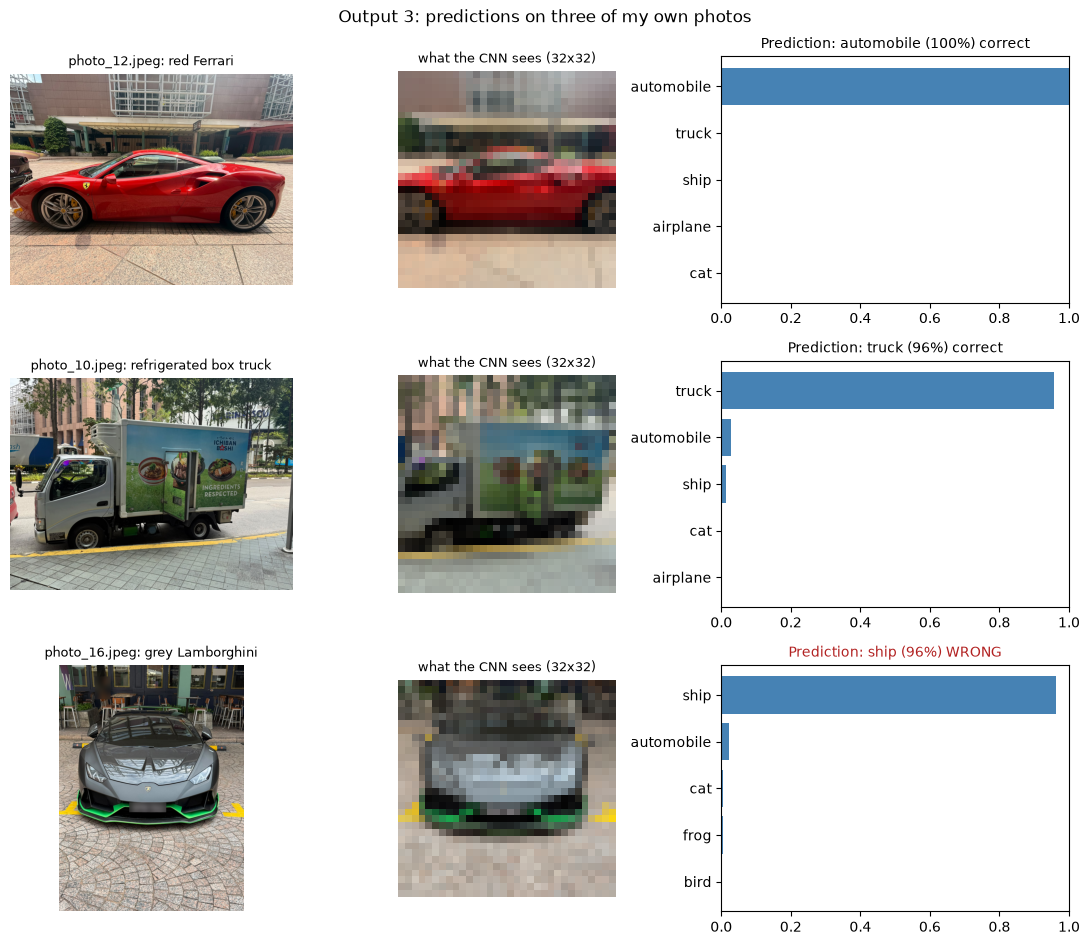

In [2]:
THREE = ["photo_12.jpeg", "photo_10.jpeg", "photo_16.jpeg"]
fig, axes = plt.subplots(3, 3, figsize=(11, 9.6), gridspec_kw={"width_ratios": [1.3, 1, 1.6]})
for row, name in enumerate(THREE):
    path = PHOTOS / name; x = load_for_cnn(path); p = probs_keras(x); top = np.argsort(p)[::-1][:5]
    axes[row, 0].imshow(for_display(path)); axes[row, 0].set_title(f"{name}: {labels[name]['description']}", fontsize=9)
    axes[row, 1].imshow(x); axes[row, 1].set_title("what the CNN sees (32x32)", fontsize=9)
    axes[row, 2].barh([CLASS_NAMES[i] for i in top][::-1], p[top][::-1], color="steelblue")
    axes[row, 2].set_xlim(0, 1)
    ok = CLASS_NAMES[top[0]] == labels[name]["true_class"]
    axes[row, 2].set_title(f"Prediction: {CLASS_NAMES[top[0]]} ({p[top[0]]:.0%}) " + ("correct" if ok else "WRONG"), fontsize=10,
                           color="black" if ok else "firebrick")
    for ax in axes[row, :2]: ax.axis("off")
    print(f"{name}: true {labels[name]['true_class']:<10} -> " + ", ".join(f"{CLASS_NAMES[i]} {p[i]:.1%}" for i in top[:3]))
fig.suptitle("Output 3: predictions on three of my own photos"); plt.tight_layout()
fig.savefig(OUT / "own_photos_three.png", dpi=150); plt.show()

## All 18 photos: does the viewpoint matter?

Vans and photo 9 (two vehicles) are listed but not scored, because CIFAR-10 has no van class and photo 9 has no single right answer.
The full Keras model and the int8 model used on the robot are both run.

In [3]:
rows = []
for name in sorted(labels):
    x = load_for_cnn(PHOTOS / name); pk, pq = probs_keras(x), probs_int8(x)
    k, q = int(pk.argmax()), int(pq.argmax()); info = labels[name]
    scored = info["true_class"] in CLASS_NAMES
    rows.append(dict(file=name, true_class=info["true_class"], view=info["view"], keras_label=CLASS_NAMES[k],
                     keras_conf=round(float(pk[k]), 3), int8_label=CLASS_NAMES[q], int8_conf=round(float(pq[q]), 3),
                     scored=scored, correct=(CLASS_NAMES[k] == info["true_class"]) if scored else ""))
with open(OUT / "own_photos_predictions.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
for r in rows:
    mark = "" if not r["scored"] else ("ok" if r["correct"] else "WRONG")
    print(f"{r['file']}  {r['true_class']:<10} {r['view']:<9} keras {r['keras_label']:<10} {r['keras_conf']:.0%}   int8 {r['int8_label']:<10} {r['int8_conf']:.0%}  {mark}")

scored = [r for r in rows if r["scored"]]
print(f"\nScored photos: {sum(r['correct'] for r in scored)} of {len(scored)} correct")
for view in ["side", "front", "rear", "close-up"]:
    v = [r for r in scored if r["view"] == view]
    print(f"  {view:<9}: {sum(r['correct'] for r in v)} of {len(v)} correct")
print(f"int8 model agrees with Keras on {sum(r['keras_label'] == r['int8_label'] for r in rows)} of {len(rows)} photos")

photo_01.jpeg  van        side      keras truck      73%   int8 truck      69%  
photo_02.jpeg  van        side      keras automobile 96%   int8 automobile 97%  
photo_03.jpeg  van        front     keras truck      92%   int8 truck      89%  
photo_04.jpeg  van        rear      keras automobile 49%   int8 automobile 50%  
photo_05.jpeg  automobile front     keras automobile 100%   int8 automobile 100%  ok
photo_06.jpeg  automobile side      keras automobile 96%   int8 automobile 95%  ok
photo_07.jpeg  automobile rear      keras ship       75%   int8 ship       74%  WRONG
photo_08.jpeg  automobile close-up  keras airplane   89%   int8 airplane   92%  WRONG
photo_09.jpeg  mixed      side      keras automobile 98%   int8 automobile 98%  
photo_10.jpeg  truck      side      keras truck      96%   int8 truck      96%  ok
photo_11.jpeg  truck      side      keras truck      99%   int8 truck      99%  ok
photo_12.jpeg  automobile side      keras automobile 100%   int8 automobile 100%  ok
phot

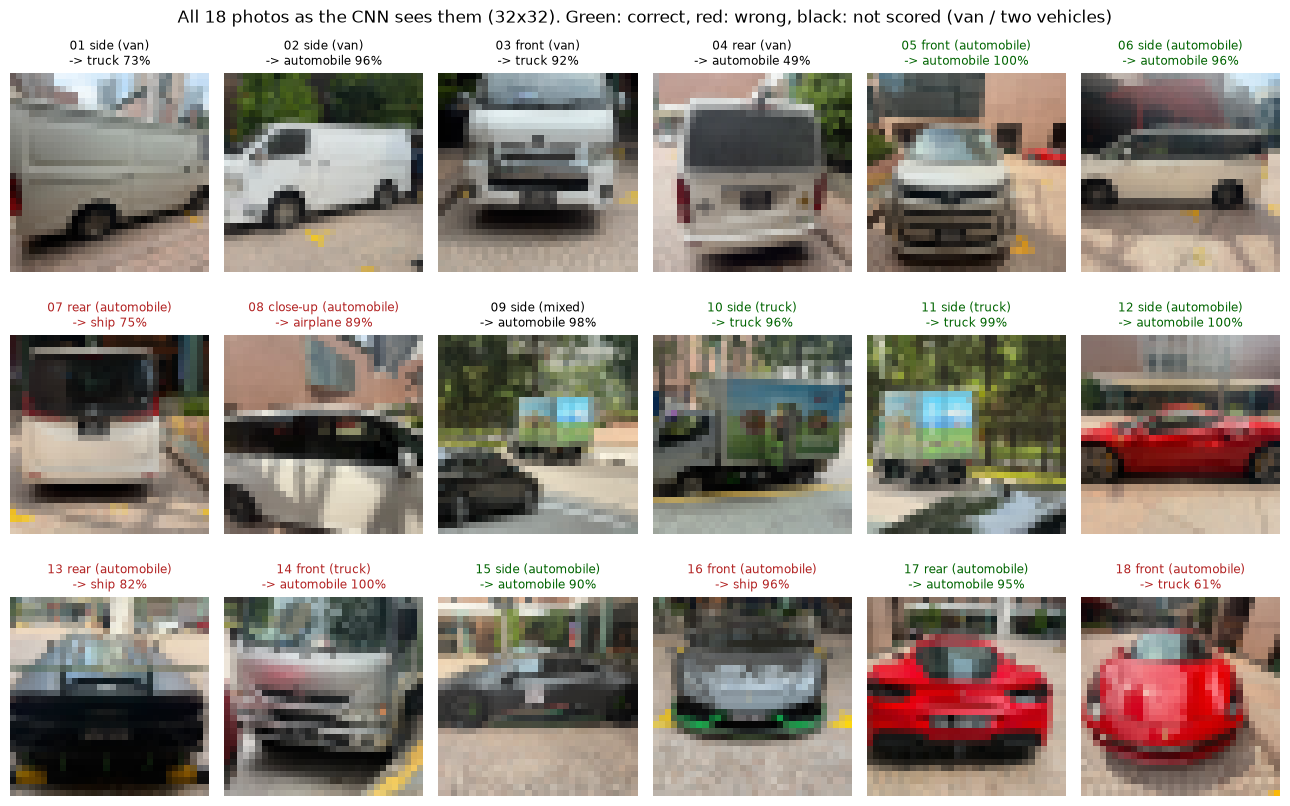

In [4]:
fig, axes = plt.subplots(3, 6, figsize=(13, 8.4))
for ax, r in zip(axes.flat, rows):
    ax.imshow(load_for_cnn(PHOTOS / r["file"])); ax.axis("off")
    colour = "black" if not r["scored"] else ("darkgreen" if r["correct"] else "firebrick")
    ax.set_title(f"{r['file'][6:8]} {r['view']} ({r['true_class']})\n-> {r['keras_label']} {r['keras_conf']:.0%}", fontsize=8.5, color=colour)
fig.suptitle("All 18 photos as the CNN sees them (32x32). Green: correct, red: wrong, black: not scored (van / two vehicles)")
plt.tight_layout(h_pad=2.2); fig.savefig(OUT / "own_photos_all.png", dpi=150); plt.show()

## What this shows

* **Side views are recognised; front and rear views often are not.** CIFAR-10's car and truck photos are mostly side or three-quarter views with the wheels visible. Seen head-on or from behind, a low, wide car on a large area of grey paving is a horizontal shape on a uniform textured background, which is what CIFAR-10's *ship* photos look like.
* **Wrong answers can be very confident** (photo 16: ship 96%), so the softmax score is not a reliable sign of correctness, the same lesson as the Webots dog.
* **The robot's int8 model gives the same top label as the full model**, so quantisation does not change these results.
* With no van class, vans are split between *truck* and *automobile*, which is a sensible answer from a closed set of ten classes.